# Reduced EvoPro GA Analysis

Benchmark the EvoPro-style genetic algorithm on the simplified sequence
problem. This notebook compares different operator modes (mutation-only,
crossover-only, both) using multiple repeats, convergence analysis and
non-parametric statistical tests.



In [132]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

NOTEBOOK_ROOT = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Notebook root: {NOTEBOOK_ROOT}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Notebook root: /home/david/Documents/Dev/Tesis/evopro/EvoPro_Reduced/notebooks


In [133]:
from reduced_problem import ReducedEvoProConfig, ReducedEvoProProblem
from reduced_ga import GeneticAlgorithmReduced
from convergence import ConvergenceAnalyzer

import pandas as pd
import numpy as np



In [134]:
CONFIG_PATH = PROJECT_ROOT / "data/default_config.json"
config = ReducedEvoProConfig.from_json(CONFIG_PATH)
problem = ReducedEvoProProblem(config)

print(f"Sequence length: {config.sequence_length}")
print(f"Alphabet: {config.alphabet}")
config.weights


Sequence length: 60
Alphabet: ACDEFGHIKLMNPQRSTVWY


{'disorder': 1.0,
 'hydrophobic_core': -1.5,
 'charge_balance': 0.8,
 'motif': -2.0}

In [135]:
def run_experiment(mode: str, repeats: int = 30, iterations: int = 150, pool_size: int = 80,
                   mutation_rate: float = 0.1, crossover_percent: float = 0.9,
                   seed_offset: int = 100) -> tuple[pd.DataFrame, dict[str, list[np.ndarray]]]:
    """Run multiple GA repeats for a given mode; returns results and score trajectories."""
    results = []
    trajectories = {
        "best_scores": [],
        "avg_scores": [],
        "std_scores": [],
        "range_scores": [],
    }
    for repeat in range(1, repeats + 1):
        seed = seed_offset + repeat
        ga = GeneticAlgorithmReduced(
            problem=problem,
            pool_size=pool_size,
            mutation_rate=mutation_rate,
            crossover_percent=crossover_percent,
            minimize=True,
            random_seed=seed,
            mode=mode,
        )
        best_seq, best_score = ga.run(num_iterations=iterations, verbose=False)
        analyzer = ConvergenceAnalyzer(ga)
        metrics = analyzer.get_convergence_metrics()

        trajectories["best_scores"].append(metrics['best_scores_per_iter'])
        trajectories["avg_scores"].append(metrics['avg_scores_per_iter'])
        trajectories["std_scores"].append(metrics['std_scores_per_iter'])
        range_scores = [max_s - min_s for max_s, min_s in zip(metrics['max_scores_per_iter'], metrics['min_scores_per_iter'])]
        trajectories["range_scores"].append(range_scores)

        results.append({
            "mode": mode,
            "repeat": repeat,
            "seed": seed,
            "initial_score": metrics['initial_best_score'],
            "final_score": metrics['final_best_score'],
            "total_improvement": metrics['total_improvement'],
            "avg_improvement": metrics['avg_improvement_per_iter'],
            "converged": metrics['converged'],
            "iterations": metrics['num_iterations'],
            "iterations_with_improvement": sum(1 for imp in metrics['improvements'] if imp > 0),
            "best_sequence": problem.sequence_to_str(best_seq),
        })
    return pd.DataFrame(results), trajectories



In [136]:
modes = ["mutation", "crossover", "both"]
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(exist_ok=True)

all_runs = []
trajectories_by_mode = {}
for mode in modes:
    df, trajectories = run_experiment(mode=mode)
    all_runs.append(df)
    trajectories_by_mode[mode] = trajectories
    csv_path = results_dir / f"reduced_{mode}_ga.csv"
    df.to_csv(csv_path, index=False)
    print(f"Saved {mode} results to {csv_path}")

results_df = pd.concat(all_runs, ignore_index=True)
results_df.head()


Saved mutation results to /home/david/Documents/Dev/Tesis/evopro/EvoPro_Reduced/results/reduced_mutation_ga.csv
Saved crossover results to /home/david/Documents/Dev/Tesis/evopro/EvoPro_Reduced/results/reduced_crossover_ga.csv
Saved both results to /home/david/Documents/Dev/Tesis/evopro/EvoPro_Reduced/results/reduced_both_ga.csv


,mode,repeat,seed,initial_score,final_score,total_improvement,avg_improvement,converged,iterations,iterations_with_improvement,best_sequence
0,mutation,1,101,-1.916667,-2.783333,-0.866667,0.005817,True,150,7,NHWVMMTHFRGMDDDRKCGNLYNNDAGGQEVVAAFMKYEPDPSCQI...
1,mutation,2,102,-2.683333,-2.983333,-0.300000,0.002013,True,150,2,HYNGVYGPLYQWWCTVYTGPRYTVDCGSTRLITTFSYMSDIYMPDH...
2,mutation,3,103,-1.966667,-2.800000,-0.833333,0.005593,True,150,6,RIDEYCCMSWRVDNICRYERTEMQVTRGWGHHDYHYHTLLWHTEAE...
3,mutation,4,104,-2.066667,-2.833333,-0.766667,0.005145,True,150,9,GSIPTCWGRGQGDGCMENYIGVRMNNYENKWFVINCGNYYVDQVNM...
4,mutation,5,105,-1.150000,-3.083333,-1.933333,0.012975,True,150,7,ALWENLIWMNRGEDDPYGQYTNGKSRLDPCMYKNHVVTWSYTWWLT...


In [137]:
display(results_df.groupby("mode")["final_score", "total_improvement", "avg_improvement"].describe())


final_score                                                    \
                count      mean       std       min       25%       50%   
mode                                                                      
both             30.0 -3.291111  0.157064 -3.450000 -3.412500 -3.325000   
crossover        30.0 -2.819444  0.183885 -3.266667 -2.895833 -2.783333   
mutation         30.0 -2.917222  0.113334 -3.233333 -2.966667 -2.925000   

                              total_improvement            ...            \
                75%       max             count      mean  ...       75%   
mode                                                       ...             
both      -3.237500 -2.800000              30.0 -1.532778  ... -1.033333   
crossover -2.733333 -2.383333              30.0 -1.113333  ... -0.537500   
mutation  -2.833333 -2.733333              30.0 -1.040556  ... -0.650000   

                    avg_improvement                                          \
                max           count      mean       std       min       25%   
mode                                                                          
both      -0.550000            30.0  0.010287  0.005682  0.003691  0.006935   
crossover -0.033333            30.0  0.007472  0.006187  0.000224  0.003607   
mutation  -0.166667            30.0  0.006984  0.005083  0.001119  0.004362   

                                         
                50%       75%       max  
mode                                     
both       0.008166  0.012332  0.029642  
crossover  0.006040  0.010235  0.027405  
mutation   0.005593  0.007746  0.026846  

[3 rows x 24 columns]

In [138]:
from scipy.stats import wilcoxon

metrics = ["final_score", "total_improvement", "avg_improvement"]
comparison_rows = []

for metric in metrics:
    pivot = results_df.pivot(index="seed", columns="mode", values=metric)
    for a, b in [("mutation", "crossover"), ("both", "crossover"), ("both", "mutation")]:
        stat, p_value = wilcoxon(pivot[a], pivot[b])
        comparison_rows.append({
            "metric": metric,
            "method_a": a,
            "method_b": b,
            "test": "Wilcoxon",
            "statistic": stat,
            "p_value": p_value,
        })

comparison_df = pd.DataFrame(comparison_rows)
comparison_df


,metric,method_a,method_b,test,statistic,p_value
0,final_score,mutation,crossover,Wilcoxon,87.0,4.766492e-03
1,final_score,both,crossover,Wilcoxon,7.0,3.539026e-08
2,final_score,both,mutation,Wilcoxon,3.0,9.313226e-09
3,total_improvement,mutation,crossover,Wilcoxon,207.0,8.203795e-01
4,total_improvement,both,crossover,Wilcoxon,80.0,1.131454e-03
5,total_improvement,both,mutation,Wilcoxon,44.5,2.688542e-05
6,avg_improvement,mutation,crossover,Wilcoxon,207.0,8.203795e-01
7,avg_improvement,both,crossover,Wilcoxon,80.0,1.131454e-03
8,avg_improvement,both,mutation,Wilcoxon,45.0,3.049523e-05


/tmp/ipykernel_6317/1263183045.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


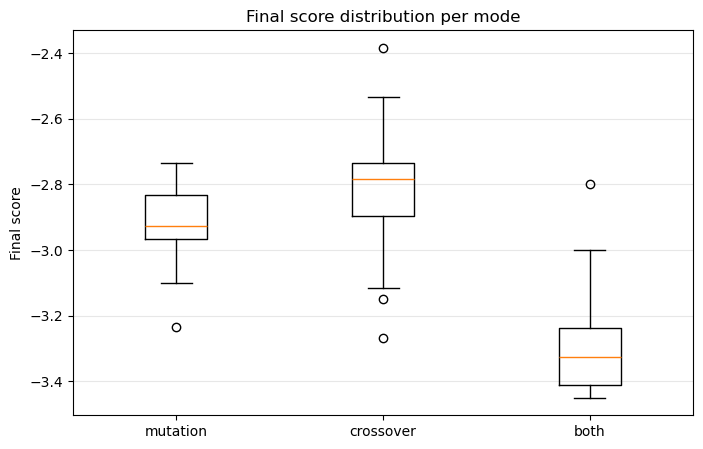

In [139]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.boxplot(
    [results_df.loc[results_df["mode"] == m, "final_score"].values for m in modes],
    labels=modes,
)
plt.ylabel("Final score")
plt.title("Final score distribution per mode")
plt.grid(True, axis='y', alpha=0.3)
plt.show()


/tmp/ipykernel_6317/1715375017.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


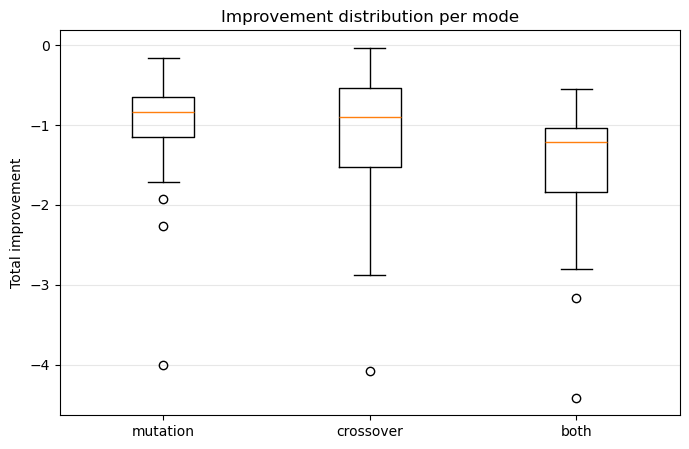

In [140]:
plt.figure(figsize=(8, 5))
plt.boxplot(
    [results_df.loc[results_df["mode"] == m, "total_improvement"].values for m in modes],
    labels=modes,
)
plt.ylabel("Total improvement")
plt.title("Improvement distribution per mode")
plt.grid(True, axis='y', alpha=0.3)
plt.show()


/tmp/ipykernel_6317/3449276504.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


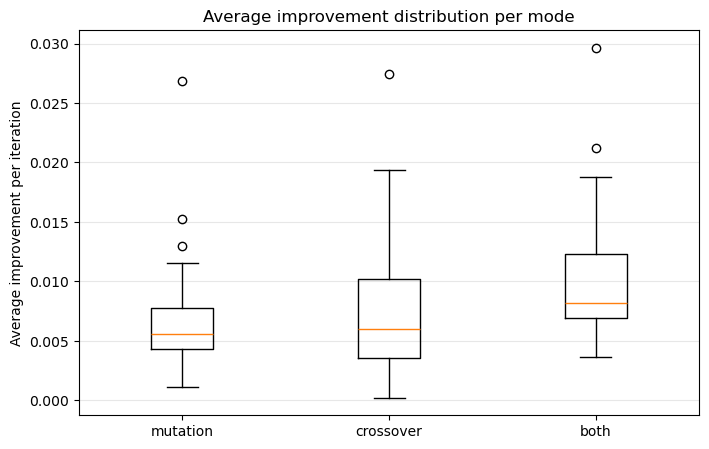

In [141]:
plt.figure(figsize=(8, 5))
plt.boxplot(
    [results_df.loc[results_df["mode"] == m, "avg_improvement"].values for m in modes],
    labels=modes,
)
plt.ylabel("Average improvement per iteration")
plt.title("Average improvement distribution per mode")
plt.grid(True, axis='y', alpha=0.3)
plt.show()


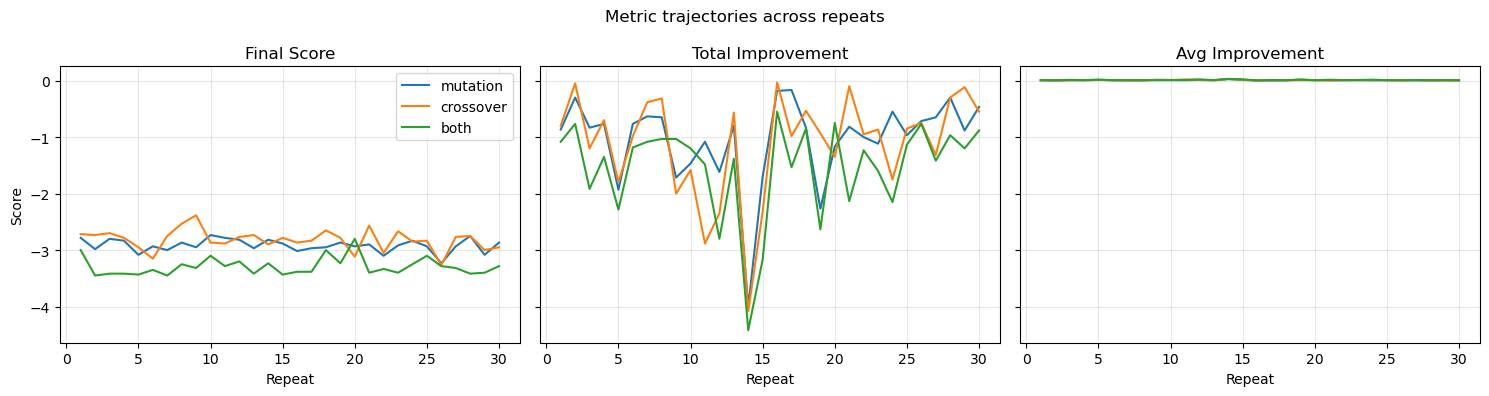

In [142]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, metric in zip(axs, ["final_score", "total_improvement", "avg_improvement"]):
    for mode in modes:
        data = results_df.loc[results_df["mode"] == mode]
        ax.plot(data["repeat"], data[metric], label=mode if ax == axs[0] else "")
    ax.set_xlabel("Repeat")
    ax.set_title(metric.replace("_", " ").title())
    ax.grid(True, alpha=0.3)
axs[0].set_ylabel("Score")
axs[0].legend()
plt.suptitle("Metric trajectories across repeats")
plt.tight_layout()
plt.show()


In [143]:
alpha = 0.05
comparison_df.assign(significant=comparison_df["p_value"] < alpha)


,metric,method_a,method_b,test,statistic,p_value,significant
0,final_score,mutation,crossover,Wilcoxon,87.0,4.766492e-03,True
1,final_score,both,crossover,Wilcoxon,7.0,3.539026e-08,True
2,final_score,both,mutation,Wilcoxon,3.0,9.313226e-09,True
3,total_improvement,mutation,crossover,Wilcoxon,207.0,8.203795e-01,False
4,total_improvement,both,crossover,Wilcoxon,80.0,1.131454e-03,True
5,total_improvement,both,mutation,Wilcoxon,44.5,2.688542e-05,True
6,avg_improvement,mutation,crossover,Wilcoxon,207.0,8.203795e-01,False
7,avg_improvement,both,crossover,Wilcoxon,80.0,1.131454e-03,True
8,avg_improvement,both,mutation,Wilcoxon,45.0,3.049523e-05,True


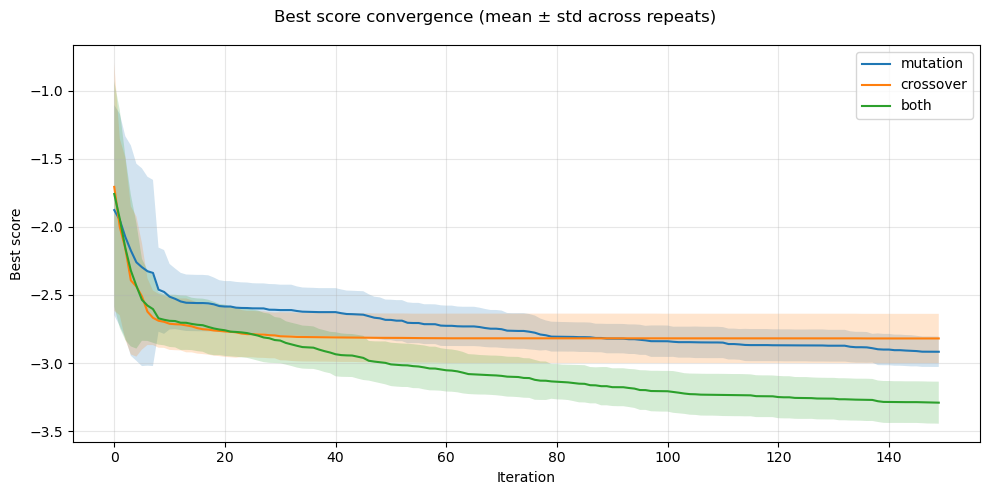

In [152]:
import matplotlib.pyplot as plt
import numpy as np

metrics_map = {
    "best_scores": ("Best score", "lower"),
}
fig, axes = plt.subplots(len(metrics_map), 1, figsize=(10, 5), sharex=True)
axes = np.atleast_1d(axes)

for ax, (key, (label, _)) in zip(axes, metrics_map.items()):
    for mode in modes:
        stacked = np.stack(trajectories_by_mode[mode][key])
        iters = np.arange(stacked.shape[1])
        mean = stacked.mean(axis=0)
        std = stacked.std(axis=0)
        ax.plot(iters, mean, label=mode)
        ax.fill_between(iters, mean - std, mean + std, alpha=0.2)
    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Iteration")
axes[0].legend()
plt.suptitle("Best score convergence (mean ± std across repeats)")
plt.tight_layout()
plt.show()